# PLTR data collection

Collect daily prices and analyst events for May 1, 2023, through April 30, 2025.

My purchase was February 1, 2024, at $16.11. The plotted marker uses that
day’s closing price, which differs from my execution price.

The collected files are saved in `../data/`. The fundamentals CSV was
collected separately and is read here for inspection.


In [1]:
import numpy as np, pandas as pd, yfinance as yf, plotly.express as px, scipy.stats as sc, requests
start, end = "2023-05-01", "2025-05-01"
purchase_date = "2024-02-01"

In [ ]:
%pip install kaleido
import plotly.io as pio
pio.renderers.default = "plotly_mimetype+png"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Daily PLTR prices

[*********************100%***********************]  1 of 1 completed


,Close,High,Low,Open,Volume
Date,,,,,
2023-05-01,7.78,7.82,7.66,7.75,19134200
2023-05-02,7.59,7.91,7.43,7.72,38008000
2023-05-03,7.56,7.68,7.45,7.62,24322400


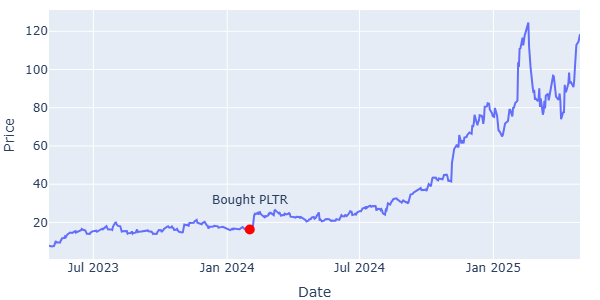

In [3]:
PLTR = yf.download("PLTR", start=start, end=end, auto_adjust=True, multi_level_index=False)
PLTR.to_csv("../data/pltr_prices.csv")

display(PLTR.head(3))
fig = px.line(PLTR, y="Close", width=600, height=300, labels={"Close":"Price"})

fig.add_scatter(x=[purchase_date], y=PLTR.loc[[purchase_date], "Close"], marker=dict(color="red", size=10), showlegend=False)
fig.add_annotation( x=purchase_date, y=PLTR.loc[purchase_date, "Close"], text="Bought PLTR", showarrow=False, yshift=30)
fig.update_layout(margin=dict(l=0, r=20, t=10, b=10)).show()

## Analyst rating and price-target events

,Firm,ToGrade,FromGrade,Action,priceTargetAction,currentPriceTarget,priorPriceTarget
GradeDate,,,,,,,
2025-04-29,RBC Capital,Underperform,Underperform,reit,Maintains,40.0,40.0
2025-04-16,Morgan Stanley,Equal-Weight,Equal-Weight,main,Lowers,90.0,95.0
2025-04-14,DA Davidson,Neutral,Neutral,main,Lowers,100.0,105.0
2025-03-13,Loop Capital,Buy,Buy,main,Lowers,125.0,141.0
2025-03-05,William Blair,Market Perform,Underperform,up,Lowers,84.0,125.0


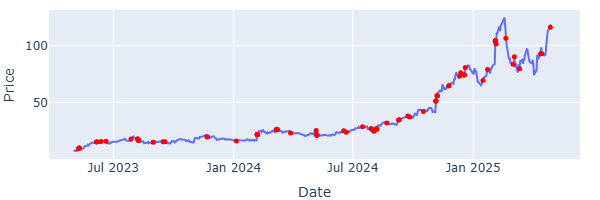

In [4]:
analysts = yf.Ticker("PLTR").get_upgrades_downgrades()

analysts.index = pd.to_datetime(analysts.index).normalize()
analysts = analysts.loc[(start <= analysts.index) & (analysts.index < end)]

analysts.to_csv("../data/analyst_events.csv")

display(analysts.head())

fig = px.line(PLTR, y="Close", width=600, height=200, labels={"Close":"Price"})

fig.add_scatter(x=analysts.index, y = PLTR.loc[analysts.index, "Close"], mode="markers", marker=dict(color="red", size=5), showlegend=False) # legend="Analyst upgrade / downgrade"
fig.update_layout(margin=dict(l=0, r=20, t=10, b=0)).show()


## Monthly mean price targets from analyst updates
Each monthly value averages the price targets reported in that month.

It is not a consensus of all active analyst forecasts.

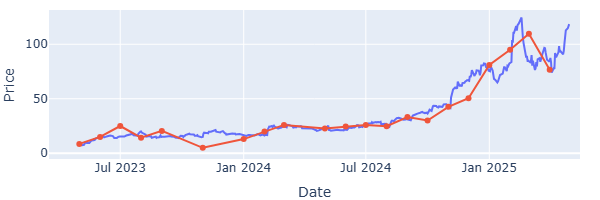

In [5]:
fig = px.line(PLTR, y="Close", width=600, height=200, labels={"Close":"Price"})
months = analysts.groupby(pd.Grouper(freq="MS"))["currentPriceTarget"].mean()

fig.add_scatter(x=months.index, y=months, mode="lines+markers", connectgaps=True, showlegend=False)
fig.update_layout(margin=dict(l=0, r=20, t=10, b=0)).show()

## SPY benchmark prices
We will use this later on, in comparisons when doing (GBM) simulation.

SPY is an ETF tracking the S&P 500.

[*********************100%***********************]  1 of 1 completed


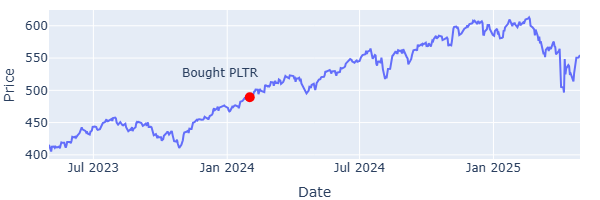

In [6]:
MARKET = yf.download("SPY", start=start, end=end, auto_adjust=False, multi_level_index=False)
MARKET.to_csv("../data/market_prices.csv")

fig = px.line(MARKET, y="Close", width=600, height=200, labels={"Close":"Price"})

fig.add_scatter(x=[purchase_date], y=MARKET.loc[[purchase_date], "Close"], marker=dict(color="red", size=10), showlegend=False)
fig.add_annotation( x=purchase_date, y=MARKET.loc[purchase_date, "Close"], text="Bought PLTR", showarrow=False, yshift=25, xshift=-30)
fig.update_layout(margin=dict(l=0, r=20, t=10, b=0)).show()

## 1.4 Quarterly revenue and diluted EPS

,period_end,eps_diluted_usd,operating_income_usd,revenue_usd,filed
0,2021-03-31,-0.07,-114014000,341234000.0,2021-05-12
1,2021-06-30,-0.07,-146148000,375642000.0,2021-08-12
2,2021-09-30,-0.05,-91941000,392146000.0,2021-11-09
3,2021-12-31,NaN,-58943000,432867000.0,2022-02-24
4,2022-03-31,-0.05,-39439000,446357000.0,2022-05-09


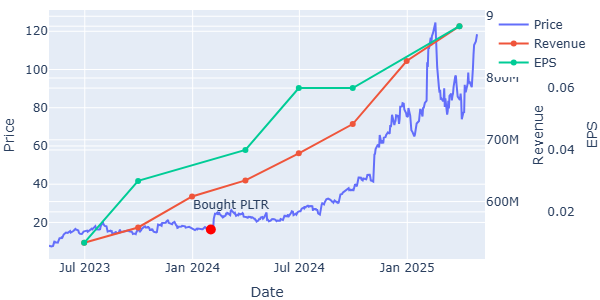

In [7]:
fundamentals = pd.read_csv("../data/fundamentals.csv")
display(fundamentals.head())

fundamentals = fundamentals[(fundamentals["period_end"] >= start) & (fundamentals["period_end"] <= end)]
fig = px.line(PLTR, y="Close", width=600, height=300, labels={"Close":"Price"}).update_traces(name="Price", showlegend=True)
fig.add_scatter(
    x=pd.to_datetime(fundamentals["period_end"]),
    y=fundamentals["revenue_usd"],
    mode="lines+markers", name="Revenue", yaxis="y2"
)
fig.add_scatter(
    x=pd.to_datetime(fundamentals["period_end"]),
    y=fundamentals["eps_diluted_usd"],
    mode="lines+markers", name="EPS", connectgaps=True, yaxis="y3"
)
fig.add_scatter(x=[purchase_date], y=PLTR.loc[[purchase_date], "Close"], marker=dict(color="red", size=10), showlegend=False)
fig.add_annotation( x=purchase_date, y=PLTR.loc[purchase_date, "Close"], text="Bought PLTR", showarrow=False, yshift=25, xshift=20)
fig.update_layout(
    yaxis2=dict(title="Revenue", overlaying="y", side="right"),
    yaxis3=dict(title="EPS", overlaying="y", side="right", anchor="free", autoshift=True),
    margin=dict(l=0, r=100, t=10, b=0)
).show()